# HW 1 Part C: Analysis and interpretation of the SIR simulation

Same model, parameters and solver as Part B (RK4, $h=0.1$ day). Results are labelled
**[numerical]** (read from the RK4 trajectory) or **[analytical]** (derived from the equations, independent of the solver),
so each numerical result can be checked against theory.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from epimodels import sir_rhs, simulate

os.makedirs("figures", exist_ok=True)

## Parameters (identical to Part B)

In [2]:
N      = 2000
y0     = np.array([1995.0, 5.0, 0.0])   # S(0), I(0), R(0)
params = {"beta": 0.125e-3,             # per person per day
          "gamma": 0.1}                 # per day
t_end  = 160                            # days
h      = 0.1                            # RK4 step (days)

beta, gamma = params["beta"], params["gamma"]
S0, I0, R0_init = y0

t, Y = simulate(sir_rhs, y0, t_end, h, params, method="rk4")
S, I, R = Y.T

---
## C(i) Infection peak

**[analytical] Peak condition.** $\dfrac{dI}{dt}=I(\beta S-\gamma)$. While $I>0$, $I$ grows when $S>\gamma/\beta$ and
shrinks when $S<\gamma/\beta$, so the maximum of $I$ occurs exactly when
$$S(t_\text{peak})=S^*=\frac{\gamma}{\beta}=\frac{0.1}{0.125\times10^{-3}}=800\ \text{people}.$$

**[analytical] Peak height.** Dividing $dI/dt$ by $dS/dt$ gives $\dfrac{dI}{dS}=-1+\dfrac{\gamma}{\beta S}$, which integrates to a
conserved quantity
$$V(S,I)=S+I-\frac{\gamma}{\beta}\ln S=\text{const}.$$
Evaluating $V$ at $t=0$ and at the peak ($S=S^*$):
$$I_\text{max}=I_0+S_0-S^*-S^*\ln\frac{S_0}{S^*}.$$
The peak **time** has no closed form, so it is found numerically.

In [3]:
S_star = gamma / beta
I_max_exact = I0 + S0 - S_star - S_star * np.log(S0 / S_star)
print(f"[analytical] S* = gamma/beta = {S_star:.1f} people")
print(f"[analytical] I_max = {I_max_exact:.4f} people")

[analytical] S* = gamma/beta = 800.0 people
[analytical] I_max = 468.9699 people


**[numerical] Peak from the RK4 grid.** The grid has spacing $h=0.1$ day, so `argmax` locates the peak only to within
$\pm h/2=\pm0.05$ day. Two sub-grid estimates refine it:
1. a parabola through the three grid points around the maximum;
2. the time at which $S(t)$ crosses $S^*=800$ (linear interpolation), which by the analysis above *is* the peak time.

In [4]:
k = int(np.argmax(I))
print(f"[numerical] grid maximum:   day {t[k]:.1f}, I = {I[k]:.4f} people  (resolution ±{h/2} day)")

# 1) parabolic interpolation through I[k-1], I[k], I[k+1]
y1, y2, y3 = I[k-1:k+2]
delta = 0.5 * (y1 - y3) / (y1 - 2*y2 + y3)          # offset in steps, |delta| <= 0.5
t_peak_par = t[k] + delta * h
I_peak_par = y2 - 0.25 * (y1 - y3) * delta
print(f"[numerical] parabolic fit:  day {t_peak_par:.3f}, I = {I_peak_par:.4f} people")

# 2) time at which S crosses S* (= peak time)
j = int(np.argmax(S < S_star))                       # first grid point with S below S*
t_cross = t[j-1] + (S[j-1] - S_star) / (S[j-1] - S[j]) * h
print(f"[numerical] S crosses S*:   day {t_cross:.3f}")

# Peak condition checked directly: dI/dt changes sign at the grid maximum
dIdt = [sir_rhs(0, Y[i], params)[1] for i in (k-1, k, k+1)]
print("dI/dt at days", [f"{t[i]:.1f}" for i in (k-1, k, k+1)], "=", [f"{v:+.3f}" for v in dIdt], "people/day")
print(f"S at grid maximum = {S[k]:.2f}  (S* = {S_star:.0f})")

[numerical] grid maximum:   day 42.5, I = 468.9672 people  (resolution ±0.05 day)
[numerical] parabolic fit:  day 42.544, I = 468.9699 people
[numerical] S crosses S*:   day 42.544
dI/dt at days ['42.4', '42.5', '42.6'] = ['+0.398', '+0.122', '-0.153'] people/day
S at grid maximum = 802.08  (S* = 800)


In [5]:
# Comparison with the analytical peak height, and a finer-step cross-check of the peak time
print(f"|I_peak (parabolic) - I_max (analytical)| = {abs(I_peak_par - I_max_exact):.2e} people")
print(f"|I[k] (grid)        - I_max (analytical)| = {abs(I[k] - I_max_exact):.2e} people")

t_f, Y_f = simulate(sir_rhs, y0, t_end, 0.01, params, method="rk4")
k_f = int(np.argmax(Y_f[:, 1]))
print(f"RK4 with h = 0.01: grid peak at day {t_f[k_f]:.2f}, I = {Y_f[k_f,1]:.4f}  -> confirms the h = 0.1 estimate")

# The conserved quantity V should be constant along the numerical trajectory
V = S + I - S_star * np.log(S)
print(f"max |V(t) - V(0)| along the RK4 trajectory = {np.abs(V - V[0]).max():.2e}")

|I_peak (parabolic) - I_max (analytical)| = 9.44e-06 people
|I[k] (grid)        - I_max (analytical)| = 2.69e-03 people


RK4 with h = 0.01: grid peak at day 42.54, I = 468.9699  -> confirms the h = 0.1 estimate
max |V(t) - V(0)| along the RK4 trajectory = 9.99e-09


**What determines the peak.**
* The peak occurs when the infection flow $\beta SI$ equals the recovery flow $\gamma I$; this happens when the susceptible
  pool has been depleted to $S^*=\gamma/\beta$ — it does not depend on $I_0$ or on time.
* **Height:** set by $S_0$, $I_0$ and $S^*=\gamma/\beta$ only (formula above). The larger $S_0$ is relative to $S^*$
  (i.e. the larger $R_0$), the more people are infectious at once.
* **Timing:** set by the early growth rate $r=\beta S_0-\gamma$ (see C(ii)) and by $I_0$: with fewer initial cases
  it takes longer to reach the same depletion, so the peak is later but (for $I_0\ll N$) about equally high.

---
## C(ii) Basic reproduction number

$R_0=\beta N/\gamma$ = (contacts that transmit per day in a fully susceptible population, $\beta N$) × (mean infectious
period, $1/\gamma$) = expected number of secondary infections caused by one infected person in a fully susceptible population.

**[analytical] Links to growth and decline.**
* Early growth: with $S\approx S_0$, $dI/dt\approx(\beta S_0-\gamma)I=\gamma\big(R_0\tfrac{S_0}{N}-1\big)I$ → exponential growth
  with rate $r=\beta S_0-\gamma$ if $R_0 S_0/N>1$, decay otherwise.
* Later: the *effective* reproduction number $R_t=\beta S(t)/\gamma=R_0\,S(t)/N$ falls as susceptibles are used up. $I$ peaks when
  $R_t=1$ (equivalently $S=S^*$) and declines afterwards.
* Herd-immunity threshold: $R_t<1$ once a fraction $1-1/R_0$ of the population is no longer susceptible.

In [6]:
R0 = beta * N / gamma
r = beta * S0 - gamma
print(f"[analytical] R0 = beta*N/gamma = {R0:.2f}")
print(f"[analytical] initial growth rate r = beta*S0 - gamma = {r:.4f} /day, doubling time ln2/r = {np.log(2)/r:.2f} days")
print(f"[analytical] herd-immunity threshold 1 - 1/R0 = {1 - 1/R0:.0%}  (i.e. S < N/R0 = {N/R0:.0f} people)")

# [numerical] early growth rate: slope of ln I(t) over the first 10 days
m = t <= 10
r_num = np.polyfit(t[m], np.log(I[m]), 1)[0]
print(f"[numerical]  fitted growth rate of ln I(t), days 0-10 = {r_num:.4f} /day")

# Thresholds for control (R0 < 1)
print(f"Control requires R0 < 1: beta < gamma/N = {gamma/N:.2e} /person/day (a {1 - 1/R0:.0%} cut in transmission),")
print(f"                         or gamma > beta*N = {beta*N:.2f} /day (mean infectious period < {1/(beta*N):.1f} days)")

[analytical] R0 = beta*N/gamma = 2.50
[analytical] initial growth rate r = beta*S0 - gamma = 0.1494 /day, doubling time ln2/r = 4.64 days
[analytical] herd-immunity threshold 1 - 1/R0 = 60%  (i.e. S < N/R0 = 800 people)
[numerical]  fitted growth rate of ln I(t), days 0-10 = 0.1481 /day
Control requires R0 < 1: beta < gamma/N = 5.00e-05 /person/day (a 60% cut in transmission),
                         or gamma > beta*N = 0.25 /day (mean infectious period < 4.0 days)


**Interpretation.** $R_0=2.5$: in a fully susceptible population each case infects on average 2.5 others, so the
outbreak grows. Control means pushing the effective reproduction number below 1:
* **reduce $\beta$** (distancing, masks, isolation) — a 60 % reduction in transmission gives $R_0=1$;
* **increase $\gamma$** (faster diagnosis/treatment/isolation shortens the infectious period) — the infectious period would have
  to fall from 10 to below 4 days;
* **reduce $S$** (vaccination) — immunizing more than $1-1/R_0=60\%$ prevents growth altogether.

Even when $R_0$ stays above 1, lowering it raises $S^*=\gamma/\beta$, which lowers and delays the peak ("flattening the curve").

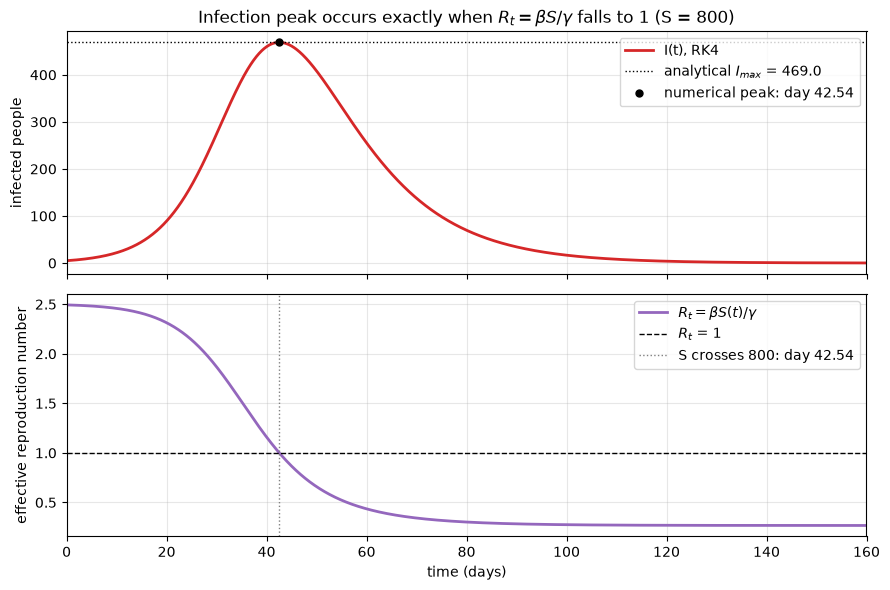

In [7]:
Rt = beta * S / gamma
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax1.plot(t, I, color="tab:red", lw=2, label="I(t), RK4")
ax1.axhline(I_max_exact, color="k", ls=":", lw=1, label=f"analytical $I_{{max}}$ = {I_max_exact:.1f}")
ax1.plot(t_peak_par, I_peak_par, "ko", ms=5, label=f"numerical peak: day {t_peak_par:.2f}")
ax1.set_ylabel("infected people"); ax1.legend(loc="upper right"); ax1.grid(alpha=.3)
ax1.set_title("Infection peak occurs exactly when $R_t=\\beta S/\\gamma$ falls to 1 (S = 800)")

ax2.plot(t, Rt, color="tab:purple", lw=2, label=r"$R_t=\beta S(t)/\gamma$")
ax2.axhline(1, color="k", ls="--", lw=1, label="$R_t$ = 1")
ax2.axvline(t_cross, color="gray", ls=":", lw=1, label=f"S crosses 800: day {t_cross:.2f}")
ax2.set_xlabel("time (days)"); ax2.set_ylabel("effective reproduction number")
ax2.set_xlim(0, t_end); ax2.legend(loc="upper right"); ax2.grid(alpha=.3)
plt.tight_layout(); plt.savefig("figures/partC_peak_and_Rt.png", dpi=150); plt.show()

---
## C(iii) Epidemic dynamics

**[analytical] Final size.** Evaluating the conserved quantity $V$ at $t=0$ and $t\to\infty$ (where $I\to0$), with $R(0)=0$:
$$\ln\frac{S_0}{S_\infty}=\frac{\beta}{\gamma}\,(N-S_\infty).$$
This has one root in $(0,S^*)$, found below by bisection (no ODE solver involved).

In [8]:
# Values at day 160 [numerical]
S160, I160, R160 = Y[-1]
print(f"[numerical] day 160: S = {S160:.2f}, I = {I160:.3f}, R = {R160:.2f}  (sum = {Y[-1].sum():.6f})")
print(f"[numerical] never infected by day 160 = S(160) = {S160:.2f} people ({S160/N:.1%} of N)")
print(f"[numerical] new infections by day 160 = S0 - S(160) = {S0 - S160:.2f}; "
      f"ever infected incl. the 5 initial cases = {N - S160:.2f}")

# Final size S_inf [analytical]: solve g(S) = ln(S0/S) - (beta/gamma)(N - S) = 0 on (0, S*)
g = lambda s: np.log(S0 / s) - (beta / gamma) * (N - s)
lo, hi = 1e-9, S_star                    # g(lo) > 0, g(S*) < 0
for _ in range(200):
    mid = 0.5 * (lo + hi)
    lo, hi = (mid, hi) if g(mid) > 0 else (lo, mid)
S_inf = 0.5 * (lo + hi)
print(f"[analytical] S_inf (t -> infinity) = {S_inf:.2f} people never infected  ({S_inf/N:.1%} of N)")
print(f"            still to be infected after day 160: S(160) - S_inf = {S160 - S_inf:.2f} people")
print(f"            overshoot beyond the herd-immunity threshold: S* - S_inf = {S_star - S_inf:.2f} people")

# [numerical] confirm with a longer simulation
t_l, Y_l = simulate(sir_rhs, y0, 600, h, params, method="rk4")
print(f"[numerical] RK4 to day 600: S = {Y_l[-1,0]:.2f}, I = {Y_l[-1,1]:.1e}  -> matches S_inf")

[numerical] day 160: S = 214.05, I = 0.208, R = 1785.74  (sum = 2000.000000)
[numerical] never infected by day 160 = S(160) = 214.05 people (10.7% of N)
[numerical] new infections by day 160 = S0 - S(160) = 1780.95; ever infected incl. the 5 initial cases = 1785.95
[analytical] S_inf (t -> infinity) = 213.98 people never infected  (10.7% of N)
            still to be infected after day 160: S(160) - S_inf = 0.08 people
            overshoot beyond the herd-immunity threshold: S* - S_inf = 586.02 people
[numerical] RK4 to day 600: S = 213.98, I = 2.1e-15  -> matches S_inf


In [9]:
# Conservation check over the whole 160-day run
total = Y.sum(axis=1)
print(f"S+I+R ranges over [{total.min():.10f}, {total.max():.10f}];  max |S+I+R - N| = {np.abs(total - N).max():.2e}")
assert np.allclose(total, N, rtol=0, atol=1e-8)

S+I+R ranges over [2000.0000000000, 2000.0000000000];  max |S+I+R - N| = 3.18e-12


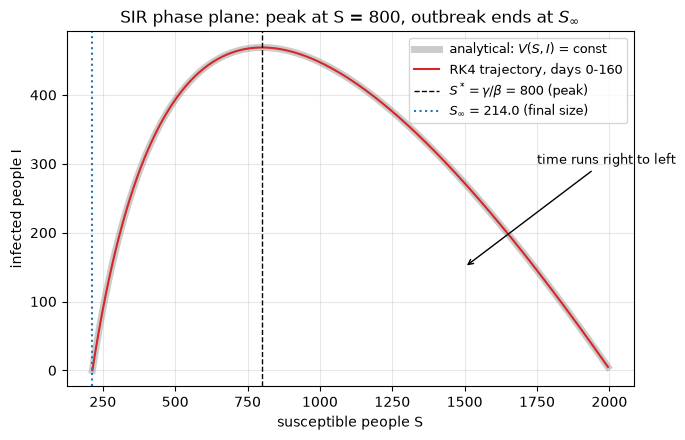

In [10]:
# Phase plane: numerical trajectory vs analytical conserved-quantity curve
S_grid = np.linspace(S_inf, S0, 400)
I_curve = I0 + S0 - S_grid + S_star * np.log(S_grid / S0)     # from V(S, I) = V(S0, I0)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(S_grid, I_curve, color="0.6", lw=5, alpha=.5, label="analytical: $V(S,I)$ = const")
ax.plot(S, I, color="tab:red", lw=1.5, label="RK4 trajectory, days 0-160")
ax.axvline(S_star, color="k", ls="--", lw=1, label=f"$S^*=\\gamma/\\beta$ = {S_star:.0f} (peak)")
ax.axvline(S_inf, color="tab:blue", ls=":", lw=1.5, label=f"$S_\\infty$ = {S_inf:.1f} (final size)")
ax.annotate("time runs right to left", xy=(1500, 150), xytext=(1750, 300),
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_xlabel("susceptible people S"); ax.set_ylabel("infected people I")
ax.set_title("SIR phase plane: peak at S = 800, outbreak ends at $S_\\infty$")
ax.legend(loc="upper right", fontsize=9); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("figures/partC_phase_plane.png", dpi=150); plt.show()

**Description of the dynamics.**
* **S(t)** decreases monotonically ($dS/dt=-\beta SI\le0$): slowly at first (few infectious people), fastest around the peak of $I$
  (where $\beta SI$ is largest), then levels off.
* **I(t)** rises roughly exponentially while $R_t>1$, peaks when $R_t=1$ ($S=800$), then decays; once $S\ll S^*$ the decay
  approaches $e^{-(\gamma-\beta S_\infty)t}$.
* **R(t)** increases monotonically ($dR/dt=\gamma I\ge0$), S-shaped, lagging $I$ by roughly the infectious period $1/\gamma=10$ days.
* $S+I+R=N$ throughout, so the three curves describe people **flowing** S → I → R; no one leaves or enters.

**Why infections decline although susceptibles remain.** Each infected person produces on average $R_t=\beta S/\gamma$ new
cases before recovering. After the peak $S<800$, so $R_t<1$: every generation of cases is smaller than the previous one, and
the chain of transmission dies out. The epidemic ends for lack of *infectious* people, not lack of susceptible people.
Because many people are still infectious when $S$ passes the threshold of 800, infections continue after the peak and push $S$
well below 800 (the **overshoot** $S^*-S_\infty$).

**Day 160 vs. $t\to\infty$.** $S(160)$ is the number never infected *within the simulation window*; $S_\infty$ is the number that
would never be infected if the model ran forever. Because $I(160)$ is small but not zero, $S(160)$ is slightly larger than $S_\infty$;
the difference is printed above.